# FERM — Asia 2022

This notebook manages a **complete, self-contained run**: H1 calibration, independent simulations evaluated on H2, and robustness audits. All data and code are included in this project; each run lives in a single `outputs/<run_name>/` directory.

- **`MODE = 'new'`**: compute and save a new run without overwriting previous runs.
- **`MODE = 'load'`**: read the run specified by `RUN_NAME`; do not repeat calibration, simulations or the Gravity fit.
- **`PROFILE = 'quick'`**: use smaller grids and budgets to check the workflow; these are not production results.
- **`PROFILE = 'production'`**: use the original, computationally intensive budgets.

Run the import cell to list available runs. After computing or loading a run, the plotting cell can be rerun on its own.

In [26]:
from pathlib import Path
import sys, importlib
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'FERM new github']
            if (p / 'scripts/asia_run.py').is_file())
sys.path.insert(0, str(ROOT / 'scripts'))
for name in ('ferm_model', 'asia_workflow', 'audit_workflow', 'calibration_plots',
             'test_plots', 'audit_plots', 'asia_run'):
    importlib.reload(importlib.import_module(name))
from asia_run import run_or_load, plot_run, list_runs
list_runs()

[{'name': 'quick_20261105T143850_b2f9d98e',
  'profile': 'quick',
  'status': 'complete'}]

## 1. Parameters and run selection

The main calibration compares GDP, SCI and barrier weights on a nonnegative grid that includes zero. It selects parameters by **H1** cross-entropy, with exact RM included as a candidate. SCI is log-standardized per origin; GDP is log-standardized globally. $\sigma=1$ remains fixed.

`FIT_PARTICLES_PER_ORIGIN` is the number of attempts per origin per replicate, not the number of migrants; `FIT_REPEATS` is the number of replicates to pool. `PRIOR_TOTAL` is the total number of RM-centered pseudocounts per origin. `INCLUDE_OBSERVED_MASK_CONTROL` also compares a barrier applied only to corridors with observed SCI.

`CALIBRATION` and `SIMULATION` control the main experiment. The audit uses a separate protocol in `scripts/audit_workflow.py`, selected through `PROFILE` and `AUDIT_SEED`, so its budgets remain distinct from those of the main calibration. In `load` mode, calculation parameters are ignored: the saved run configuration applies.

In [ ]:
MODE = 'new'             # 'new' or 'load'
RUN_NAME = None           # for 'load': directory name in outputs/
PROFILE = 'production'         # 'quick' or 'production'; ignored in 'load'
N_WORKERS = 2
AUDIT_SEED = 20261021

# Main H1 calibration: editable full budgets.
CALIBRATION = dict(
    GDP_GRID=(0., .125, .2, .25, .5),
    BARRIER_GRID=(0., .25, .5, 1., 2.),
    SCI_GRID=(0., .125, .25, .5),
    FIT_PARTICLES_PER_ORIGIN=20_000,
    FIT_REPEATS=2,
    SEED=20261014,
    N_WORKERS=N_WORKERS,
    PRIOR_TOTAL=50.,
    INCLUDE_OBSERVED_MASK_CONTROL=True,
)

# Independent simulations using parameters selected on H1.
SIMULATION = dict(
    N_REPLICATES=10_000,
    PARTICLES_PER_ORIGIN=200_000,
    SEED=20261016,
    N_WORKERS=N_WORKERS,
    PRIOR_TOTAL=50.,
    BAND_LEVEL=.95,
)

# Explicit reductions for the quick check; not applied in production.
if PROFILE == 'quick':
    CALIBRATION.update(GDP_GRID=(0., .25), BARRIER_GRID=(0., .25), SCI_GRID=(0., .25),
                       FIT_PARTICLES_PER_ORIGIN=500, FIT_REPEATS=2)
    SIMULATION.update(N_REPLICATES=3, PARTICLES_PER_ORIGIN=500)

# Audit to display: baseline, independent_seed or larger_fit.
EXPERIMENT = 'baseline'
FIT_ALPHA = 50.           # 5, 50 or 500
EVAL_ALPHA = 50.          # pseudocount for plotting
CMAP = 'RdBu'

## 2. Run or load

A new run has three stages:

1. **H1 calibration**: save the grid and freeze the selected parameters for each family.
2. **Independent simulations**: use the separate `SIMULATION` seed and the full-model parameters selected on H1. H2 is used for evaluation; observed origin totals are imposed, not predicted.
3. **Complete audit**: compare six SCI normalizations, historical and matched-grid families, global/observed-SCI barriers, pseudocounts $\alpha=5,50,500$, an independent seed and a fourfold H1 budget. Gravity is fitted on H1 and saved with the results. The `quick` profile covers all these categories with smaller budgets.

A run is marked complete only when every stage has finished. To reuse it, set `MODE='load'` and copy the printed run name into `RUN_NAME`.

In [28]:
run = run_or_load(mode=MODE, run_name=RUN_NAME, profile=PROFILE, workers=N_WORKERS,
                  calibration=CALIBRATION, simulation=SIMULATION, audit_seed=AUDIT_SEED)

New complete workflow: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab
Origins: 44 ; MC candidates: 11 ; fitting runs: 22
Attempts per origin/candidate: 1000
H2 has not been loaded. SCI normalization: log-z per origin.
Output: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/calibration
Fit MC 10/22
Fit MC 20/22
Fit MC 22/22
Calibration complete. Frozen parameters saved to: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/calibration/frozen_choices.json


,family,g,b,lam,train_bits
0,GDP,0.25,0.00,0.00,7.272347
1,relation,0.00,0.00,0.25,7.558309
2,GDP_relation,0.25,0.00,0.00,7.272347
3,barrier_global,0.00,0.25,0.00,7.520203
4,barrier_relation_global,0.00,0.25,0.25,6.126585
5,GDP_barrier_global,0.25,0.25,0.00,5.733010
6,GDP_barrier_relation_global,0.25,0.25,0.25,5.436364
7,barrier_observed,0.00,0.00,0.00,7.857426
8,barrier_relation_observed,0.00,0.25,0.25,6.313325
9,GDP_barrier_observed,0.25,0.25,0.00,6.134197


,g,b,lam,min_accepted,max_prior_weight,zero_acceptance_origins
candidate,,,,,,
0,0.00,0.00,0.00,NaN,0.000000,0
1,0.00,0.00,0.25,679.0,0.068587,0
2,0.00,0.25,0.00,206.0,0.195312,0
3,0.00,0.25,0.25,279.0,0.151976,0
4,0.25,0.00,0.00,725.0,0.064516,0
6,0.25,0.25,0.00,336.0,0.129534,0
7,0.25,0.25,0.25,558.0,0.082237,0
9,0.00,0.25,0.25,335.0,0.129870,0
10,0.25,0.25,0.00,392.0,0.113122,0


Upper grid boundary: GDP ['g']
Upper grid boundary: relation ['lam']
Upper grid boundary: GDP_relation ['g']
Upper grid boundary: barrier_global ['b']
Upper grid boundary: barrier_relation_global ['b', 'lam']
Upper grid boundary: GDP_barrier_global ['g', 'b']
Upper grid boundary: GDP_barrier_relation_global ['g', 'b', 'lam']
Upper grid boundary: barrier_relation_observed ['b', 'lam']
Upper grid boundary: GDP_barrier_observed ['g', 'b']
Upper grid boundary: GDP_barrier_relation_observed ['g', 'b', 'lam']
Parameters for new independent simulations:
GDP_WEIGHT = 0.25
SCI_WEIGHT = 0.25
BARRIER = 0.25
SIGMA = 1.0
SCI_NORMALIZATION = 'log_origin'
BARRIER_SUPPORT = 'global'
Use a new seed for subsequent simulations; do not reuse fitting counts as an independent check.
44 origins, 1892 corridors. H2: 6,609,518 observed counts.
Output: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/simulation
Replicate 1/3 complete
Replicate 2/3 com

,replicate,bits,gain_bits,cpc,destination_TV
0,0,6.227515,1.725575,0.331489,0.334104
1,1,5.924680,2.028409,0.340178,0.338032
2,2,5.916340,2.036749,0.336319,0.327704
3,pooled,5.844466,2.108623,0.336862,0.339680
4,RM_exact,7.953089,0.000000,0.204469,0.449132


Diagnostics: {'min_accepted': 266, 'zero_acceptance_rows': 0, 'max_prior_weight': 0.15822784810126583, 'distance_max_band_width': 0.009893192245778448, 'size_max_band_width': 0.012050739957716772}
Few replicates to estimate the tails of a 95% band; interpret with caution.
Missing SCI: 410 / 1892
Unique distributions: 52 | family memberships: 366
Fit MC calls: 153
baseline fit 1 / 52
baseline fit 21 / 52
baseline fit 41 / 52
baseline choices frozen; independent simulation complete
independent_seed fit 1 / 52
independent_seed fit 21 / 52
independent_seed fit 41 / 52
independent_seed choices frozen; independent simulation complete
larger_fit fit 1 / 52
larger_fit fit 21 / 52
larger_fit fit 41 / 52
larger_fit choices frozen; independent simulation complete
Completed: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/audit
Run complete. To reuse it: MODE="load", RUN_NAME= 'quick_20261105T151501_054822ab'


## 3. Figures and interpretation

Figures read only the selected run: calibration heatmaps, distance and flow-size CDFs, the origin-specific error map, seven FERM component models compared with RM and Gravity, and five allocation diagnostics.

Distance CDFs weight corridors by flow; flow-size CDFs give every corridor equal weight, including zeros. Bands are pointwise percentiles of **numerical Monte Carlo variability**, not prediction intervals. Metric comparisons are descriptive, without hypothesis tests.

`EXPERIMENT`, `FIT_ALPHA` and `EVAL_ALPHA` select the audit results to display. Changing them does not refit models: `FIT_ALPHA` selects a saved calibration, and `EVAL_ALPHA` regularizes saved final counts. Figures are updated in the same directories, without creating duplicates on each plotting call.

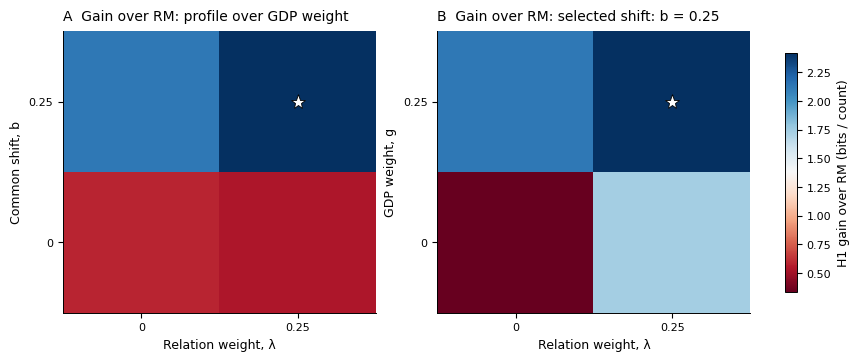

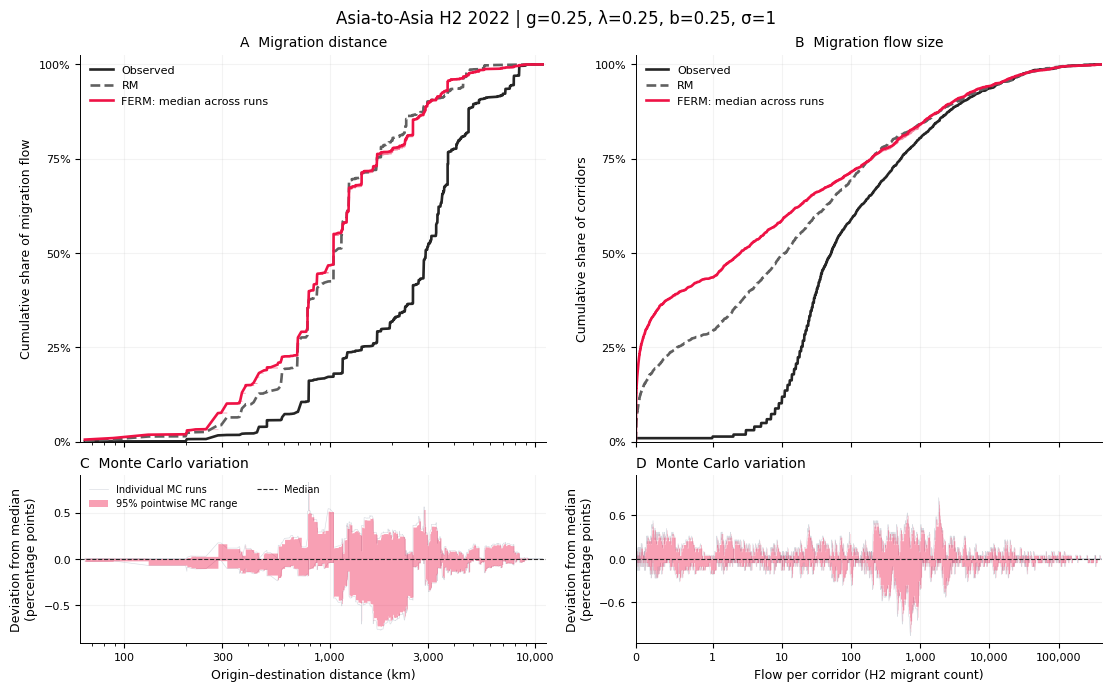

Results saved to: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/simulation
distance maximum width: 0.9893192245778448 percentage points
size maximum width: 1.2050739957716772 percentage points


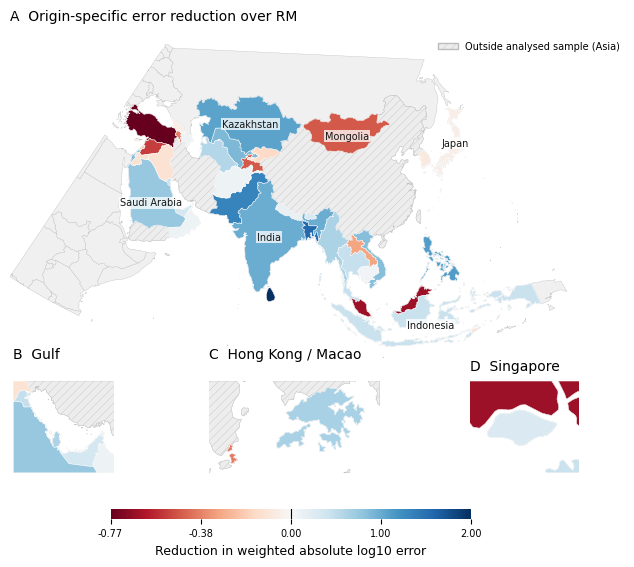

Run: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/simulation
Origins with lower weighted absolute log10 error: 27 of 44 ; range: -0.7694329569236026 2.004422237454541
Weighted mean gain: 0.6529003816742571 absolute log10 error units
Map and table saved in: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/simulation
Export: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/figures/component_distributions


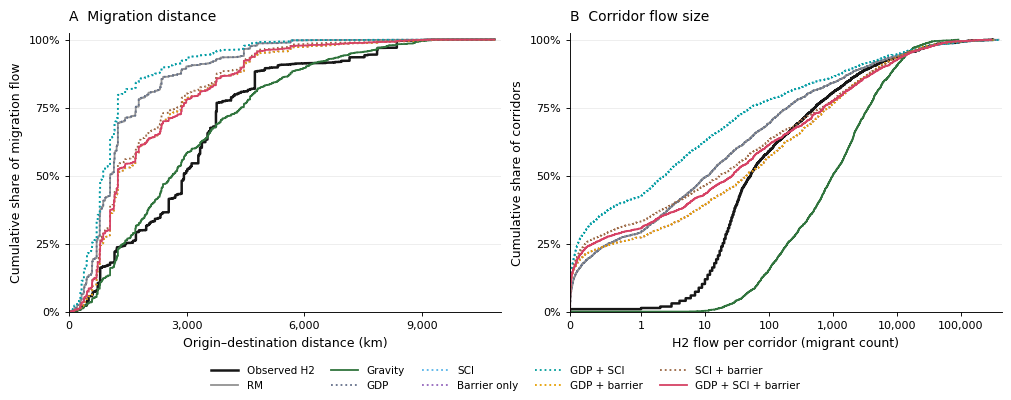

              model  distance_gap  size_gap  improved_fraction  gain_bits      cpc
                 RM      0.499044  0.397992           0.000000   0.000000 0.204469
            Gravity      0.117052  0.448203           0.505814   2.935264 0.306835
                GDP      0.499044  0.397992           0.000000   0.000000 0.204469
                SCI      0.578775  0.538584           0.182347  -0.024499 0.217555
       Barrier only      0.347187  0.312896           0.335095   1.056551 0.276979
          GDP + SCI      0.578775  0.538584           0.182347  -0.024499 0.217555
      GDP + barrier      0.347187  0.312896           0.335095   1.056551 0.276979
      SCI + barrier      0.366092  0.384778           0.324524   2.232286 0.353552
GDP + SCI + barrier      0.335885  0.357294           0.374207   2.933068 0.393471
Export: /Users/vittoriabettio/Desktop/PhD/Research/FERM/Github/FERM new github/outputs/quick_20261105T151501_054822ab/figures/metric_comparison


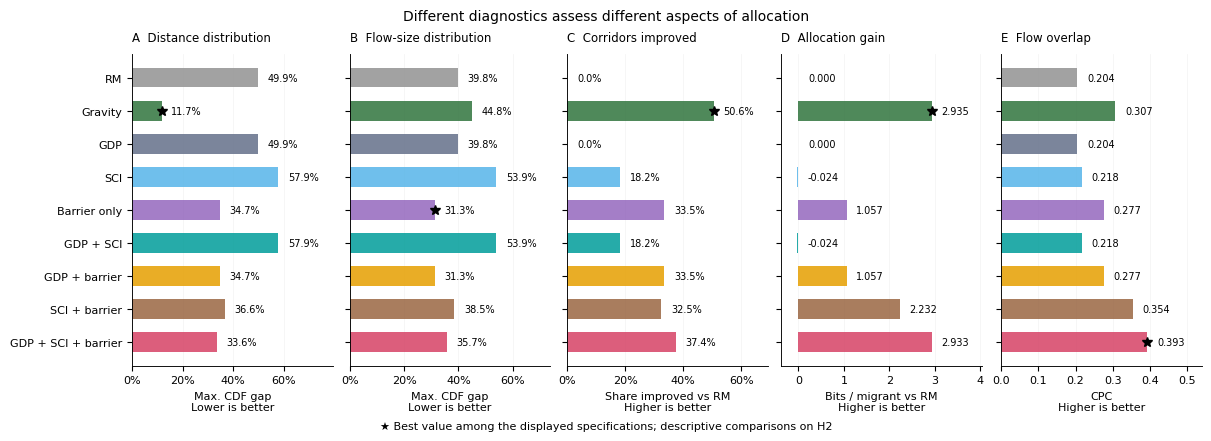

Figures for run: quick_20261105T151501_054822ab


In [29]:
# Rerun only this cell to regenerate figures: no new simulations.
plot_run(run, experiment=EXPERIMENT, fit_alpha=FIT_ALPHA, eval_alpha=EVAL_ALPHA, cmap=CMAP)